### 1. Importing libraries

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

### 2. Importing data and reading it

In [17]:
meta_path = '/content/survey_lung_cancer.csv'
data_frame = pd.read_csv(meta_path)

In [18]:
data_frame.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,MALE,69,0,1,1,0,0,1,0,1,1,1,1,1,1,YES
1,MALE,74,1,0,0,0,1,1,1,0,0,0,1,1,1,YES
2,FEMALE,59,0,0,0,1,0,1,0,1,0,1,1,0,1,NO
3,MALE,63,1,1,1,0,0,0,0,0,1,0,0,1,1,NO
4,FEMALE,63,0,1,0,0,0,0,0,1,0,1,1,0,0,NO


In [19]:
data_frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 309 non-null    object
 1   AGE                    309 non-null    int64 
 2   SMOKING                309 non-null    int64 
 3   YELLOW_FINGERS         309 non-null    int64 
 4   ANXIETY                309 non-null    int64 
 5   PEER_PRESSURE          309 non-null    int64 
 6   CHRONIC DISEASE        309 non-null    int64 
 7   FATIGUE                309 non-null    int64 
 8   ALLERGY                309 non-null    int64 
 9   WHEEZING               309 non-null    int64 
 10  ALCOHOL CONSUMING      309 non-null    int64 
 11  COUGHING               309 non-null    int64 
 12  SHORTNESS OF BREATH    309 non-null    int64 
 13  SWALLOWING DIFFICULTY  309 non-null    int64 
 14  CHEST PAIN             309 non-null    int64 
 15  LUNG_CANCER            

#### In the EDA file for the machine learning dataset, it was concluded that 6 features are required:

Selected Features:
- Wheezing
- Allergy
- Alcohol consumption
- Peer pressure

Basic Features:
- Age
- Gender

Target:
- Lung cancer


### 3. Data Processing:
* Cleaning
* Splitting
* Partitioning data

In [20]:
data = data_frame[['GENDER', 'AGE', 'WHEEZING', 'ALCOHOL CONSUMING', 'PEER_PRESSURE', 'LUNG_CANCER']]

In [21]:
data['GENDER'] = data['GENDER'].str.strip().str.upper().map({'MALE':1, 'FEMALE':0})

In [22]:
X = data.drop(axis = 1, columns = 'LUNG_CANCER')
Y = data['LUNG_CANCER']

In [23]:
print(data['GENDER'].value_counts(dropna=False))

GENDER
1    162
0    147
Name: count, dtype: int64


In [24]:
from numpy.random import RandomState
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.25, random_state=10)

standard_scale = StandardScaler()
x_train_scaled = standard_scale.fit_transform(x_train)
x_test_scaled = standard_scale.transform(x_test)

### 4. Identify the best model for the data

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

In [26]:
# Tuning Grid Parameters for Probabilistic Algorithms

log_param_grid = {
    'penalty': ['l1', 'l2', 'elasticnet', None],
    'solver': ['lbfgs', 'liblinear', 'sag', 'saga']
}

svc_param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'degree': [2, 3, 4, 5]
}

decision_param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [7, 9],
    'min_samples_split': [4, 6],
}

random_param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [3, 5, 7, 9],
    'min_samples_split': [2, 4, 6, 8],
}

gradiant_param_grid = {
    'loss': ['log_loss', 'deviance', 'exponential'],
    'learning_rate': [0.2, 0.4, 0.6],
    'n_estimators': [50, 100, 150],
}

knn_param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'] ,
    'algorithm': ['auto', 'kd_tree', 'brute'],
}

In [27]:
# Finding the best algorithm

model = [SVC(random_state=119), DecisionTreeClassifier(random_state=119),
         RandomForestClassifier(random_state=119), GradientBoostingClassifier(random_state=119),
         KNeighborsClassifier()]

param_grid = [svc_param_grid, decision_param_grid, random_param_grid, gradiant_param_grid, knn_param_grid]
for m, p in zip(model, param_grid):
    grid = GridSearchCV(estimator=m, param_grid=p, verbose=1, cv=3)
    grid.fit(x_train_scaled, y_train)

    results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 48 candidates, totalling 144 fits
Fitting 3 folds for each of 27 candidates, totalling 81 fits
Fitting 3 folds for each of 24 candidates, totalling 72 fits


### 5. Identifying and Saving the Best Model

In [28]:
best_gb_model = GradientBoostingClassifier(
    learning_rate=0.2,
    loss='exponential',
    n_estimators=50,
    random_state=119
)

best_gb_model.fit(x_train_scaled, y_train)

GradientBoostingClassifier(learning_rate=0.2, loss='exponential',
                           n_estimators=50, random_state=119)

In [29]:
import joblib

model_artifacts = {
    'model': best_gb_model,
    'scaler': standard_scale,
    'feature_names': list(X.columns)
}

joblib.dump(model_artifacts, 'ml_model.pkl')

['ml_model.pkl']

### 6. Final Model Evaluation

In [30]:
from sklearn.metrics import accuracy_score, classification_report

model = best_gb_model
pred = model.predict(x_test_scaled)

print(f"""for {m}
Accuracy Score: {accuracy_score(y_test, pred)}
Classification Report:\n{classification_report(y_test, pred)}\n""")

for KNeighborsClassifier()
Accuracy Score: 0.9102564102564102
Classification Report:
              precision    recall  f1-score   support

          NO       0.56      0.62      0.59         8
         YES       0.96      0.94      0.95        70

    accuracy                           0.91        78
   macro avg       0.76      0.78      0.77        78
weighted avg       0.92      0.91      0.91        78




### 7. Determining the Degree of Dependency Between Features

In [31]:
model = model_artifacts['model']
feature_names = model_artifacts['feature_names']

In [33]:
new_patient = pd.DataFrame([{
    'GENDER': 1,
    'AGE': 60,
    'WHEEZING': 2,
    'ALCOHOL CONSUMING': 1,
    'PEER_PRESSURE': 2
}])

features = model_artifacts['feature_names']
loaded_scaler = model_artifacts['scaler']

new_patient = new_patient[features]
new_patient_scaled = loaded_scaler.transform(new_patient)

In [34]:
importances = model.feature_importances_

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

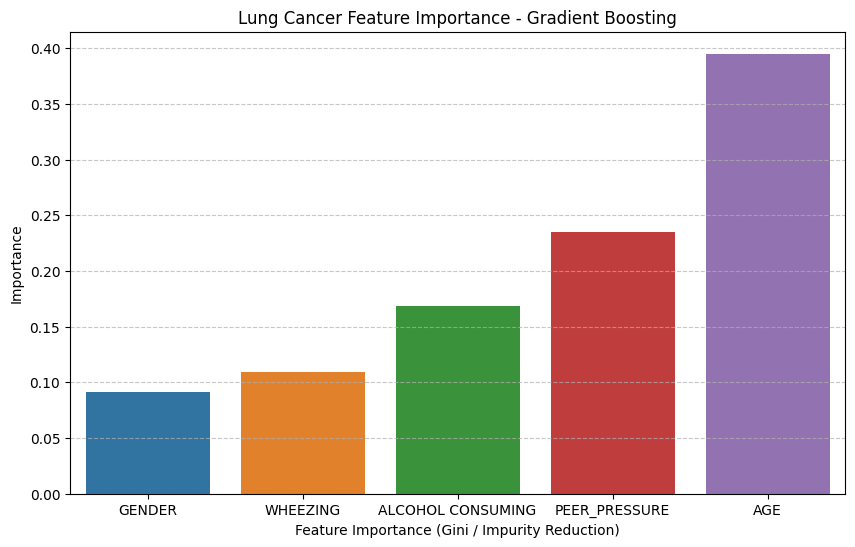

In [38]:
plt.figure(figsize=(10, 6))
sns.barplot(x=df_importance['Feature'], y=df_importance['Importance'], hue=df_importance['Feature'])
plt.xlabel("Feature Importance (Gini / Impurity Reduction)")
plt.title("Lung Cancer Feature Importance - Gradient Boosting")
plt.grid(linestyle='--', alpha=0.7, axis='y')
plt.show()



#### Scores:
- GENDER --->	1.0
- WHEEZING --->	1.2
- ALCOHOL CONSUMING --->	1.9
- PEER PRESSURE --->	2.6
- AGE --->	4.4

#### Total Points:
Total Score = (Age Score × 4.4) + (Peer Score × 2.6) + (Alcohol Score × 1.9) +    (Wheezing Score × 1.2) + (Gender Score × 1.0)

1.0 + 1.2 + 1.9 + 2.6 + 4.4 = 11.1

#### Categorization of Risk Levels (Low, Medium, High):
The total score range, from 0 to 11.1, is divided into 3 equal segments:

- Low Risk: Score from 0 to 3.7
- Medium Risk: Score from 3.8 to 7.4
- High Risk: Score from 7.5 to 11.1